In [3]:


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.decomposition import PCA

# 1. Load Student Performance Dataset
df = pd.read_csv("student_performance.csv")

print("Original Dataset:")
print(df.head())

# Select numerical columns
data = df.select_dtypes(include=np.number)

# Handle missing values
data = data.fillna(data.mean())

print("\nNumerical Dataset:")
print(data.head())

# 2. Normalization
minmax = MinMaxScaler()
normalized_data = minmax.fit_transform(data)

normalized_df = pd.DataFrame(
    normalized_data, columns=data.columns
)

print("\nNormalized Data:")
print(normalized_df.head())

# 3. Standardization
standard = StandardScaler()
standardized_data = standard.fit_transform(data)

standardized_df = pd.DataFrame(
    standardized_data, columns=data.columns
)

print("\nStandardized Data:")
print(standardized_df.head())

# 4. PCA - Dimensionality Reduction
# pca = PCA(n_components=2)
# pca_data = pca.fit_transform(standardized_data)

# pca_df = pd.DataFrame(
#     pca_data, columns=["PC1", "PC2"]
# )

# print("\nPCA Reduced Data:")
# print(pca_df.head())

# print("\nOriginal Shape:", data.shape)
# print("Reduced Shape:", pca_data.shape)

# print("\nExplained Variance Ratio:")
# print(pca.explained_variance_ratio_)

# # 5. Visualization
# plt.figure(figsize=(12, 8))

# # Normalization Graph
# plt.subplot(2, 2, 1)
# plt.plot(normalized_data[:, 0], marker='o')
# plt.title("Normalization")
# plt.xlabel("Students")
# plt.ylabel("Normalized Values")
# plt.grid()

# # Standardization Graph
# plt.subplot(2, 2, 2)
# plt.plot(standardized_data[:, 0], marker='o')
# plt.title("Standardization")
# plt.xlabel("Students")
# plt.ylabel("Standardized Values")
# plt.grid()

# # PCA Graph
# plt.subplot(2, 2, 3)
# plt.scatter(pca_data[:, 0], pca_data[:, 1])
# plt.title("PCA Dimensionality Reduction")
# plt.xlabel("Principal Component 1")
# plt.ylabel("Principal Component 2")
# plt.grid()

# # Original Data Graph
# plt.subplot(2, 2, 4)
# plt.plot(data.iloc[:, 0].values, label=data.columns[0])
# plt.plot(data.iloc[:, 1].values, label=data.columns[1])
# plt.title("Student Performance Dataset")
# plt.xlabel("Students")
# plt.ylabel("Marks / Values")
# plt.legend()
# plt.grid()

# plt.tight_layout()
# plt.show()


Original Dataset:
   Hours Studied  Previous Scores Extracurricular Activities  Sleep Hours  \
0              7               99                        Yes            9   
1              4               82                         No            4   
2              8               51                        Yes            7   
3              5               52                        Yes            5   
4              7               75                         No            8   

   Sample Question Papers Practiced  Performance Index  
0                                 1               91.0  
1                                 2               65.0  
2                                 2               45.0  
3                                 2               36.0  
4                                 5               66.0  

Numerical Dataset:
   Hours Studied  Previous Scores  Sleep Hours  \
0              7               99            9   
1              4               82            4   
2      

Original Dataset:
  Country Name Country Code      Region IncomeGroup  Year  \
0  Afghanistan          AFG  South Asia  Low income  2018   
1  Afghanistan          AFG  South Asia  Low income  2017   
2  Afghanistan          AFG  South Asia  Low income  2016   
3  Afghanistan          AFG  South Asia  Low income  2015   
4  Afghanistan          AFG  South Asia  Low income  2014   

   Birth rate per 1000 people  Death rate per 1000 people  \
0                         NaN                         NaN   
1                      33.211                       6.575   
2                      33.981                       6.742   
3                      34.809                       6.929   
4                      35.706                       7.141   

   Electric power consumption per capita           GDP  GDP per capita  \
0                                    NaN  1.936300e+10         520.897   
1                                    NaN  2.019180e+10         556.302   
2                         

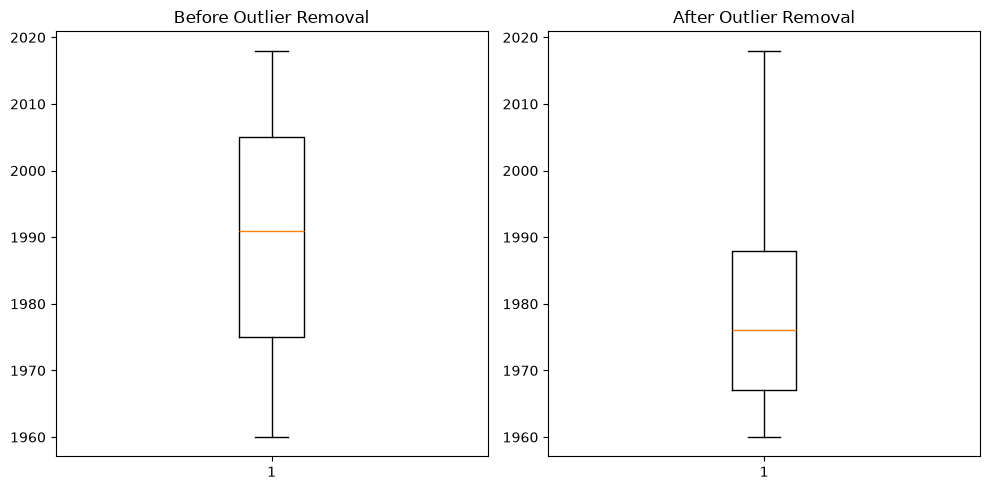


Cleaned dataset saved successfully!


In [5]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler, StandardScaler

# 1. Load Student Performance Dataset
df = pd.read_csv("World Economic Indicators - Sheet1.csv")

print("Original Dataset:")
print(df.head())

# 2. Data Cleaning

# Remove duplicate rows
df = df.drop_duplicates()

# Select numerical columns
data = df.select_dtypes(include=np.number).copy()

# Handle missing values using mean
data = data.fillna(data.mean())

print("\nCleaned Data:")
print(data.head())

# 3. Outlier Detection and Removal using IQR

Q1 = data.quantile(0.25)
Q3 = data.quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

# Remove rows containing outliers
outlier_condition = ((data < lower) | (data > upper)).any(axis=1)

print("\nNumber of Outliers:", outlier_condition.sum())

data = data[~outlier_condition]

print("\nData After Outlier Removal:")
print(data.head())

# 4. Normalization
minmax = MinMaxScaler()

normalized_data = minmax.fit_transform(data)

normalized_df = pd.DataFrame(
    normalized_data, columns=data.columns
)

print("\nNormalized Data:")
print(normalized_df.head())

# 5. Standardization
standard = StandardScaler()

standardized_data = standard.fit_transform(data)

standardized_df = pd.DataFrame(
    standardized_data, columns=data.columns
)

print("\nStandardized Data:")
print(standardized_df.head())

# 6. Display Dataset Shape
print("\nOriginal Dataset Shape:", df.shape)
print("Cleaned Dataset Shape:", data.shape)

# 7. Outlier Visualization
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.boxplot(df.select_dtypes(include=np.number).iloc[:, 0].dropna())
plt.title("Before Outlier Removal")

plt.subplot(1, 2, 2)
plt.boxplot(data.iloc[:, 0])
plt.title("After Outlier Removal")

plt.tight_layout()
plt.show()

# 8. Save Cleaned Dataset
data.to_csv("cleaned_student_performance.csv", index=False)

print("\nCleaned dataset saved successfully!")


Original Dataset:
  Country Name Country Code      Region IncomeGroup  Year  \
0  Afghanistan          AFG  South Asia  Low income  2018   
1  Afghanistan          AFG  South Asia  Low income  2017   
2  Afghanistan          AFG  South Asia  Low income  2016   
3  Afghanistan          AFG  South Asia  Low income  2015   
4  Afghanistan          AFG  South Asia  Low income  2014   

   Birth rate per 1000 people  Death rate per 1000 people  \
0                         NaN                         NaN   
1                      33.211                       6.575   
2                      33.981                       6.742   
3                      34.809                       6.929   
4                      35.706                       7.141   

   Electric power consumption per capita           GDP  GDP per capita  \
0                                    NaN  1.936300e+10         520.897   
1                                    NaN  2.019180e+10         556.302   
2                         

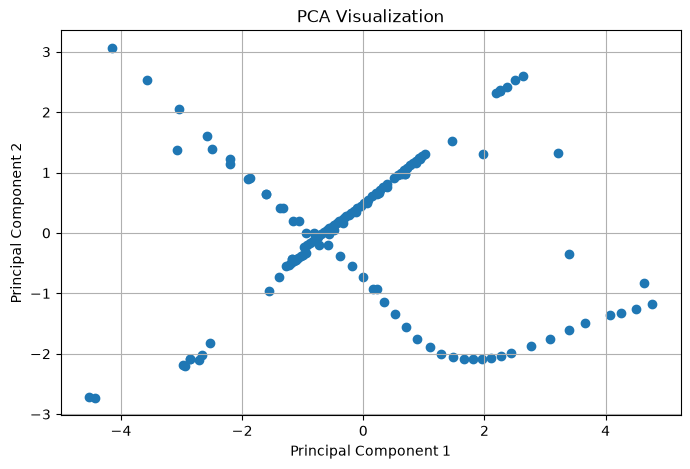


Original Dataset Shape: (499, 15)
Cleaned Dataset Shape: (133, 11)
PCA Dataset Shape: (133, 2)


In [7]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler, StandardScaler

# 1. Load Dataset
df = pd.read_csv("World Economic Indicators - Sheet1.csv")

print("Original Dataset:")
print(df.head())

# 2. Data Cleaning

# Remove duplicate rows
df = df.drop_duplicates()

# Select numerical columns
data = df.select_dtypes(include=np.number).copy()

print("\nMissing Values Before Filling:")
print(data.isnull().sum())

# Mean and Median Filling
for col in data.columns:

    if data[col].isnull().any():

        # Use median for highly skewed data
        if abs(data[col].skew()) > 0.5:
            data[col] = data[col].fillna(data[col].median())
            print(col, "-> Median Filling")

        # Use mean for approximately symmetric data
        else:
            data[col] = data[col].fillna(data[col].mean())
            print(col, "-> Mean Filling")

# Forward Fill only for country-wise yearly data
if 'Country' in df.columns and 'Year' in df.columns:

    df = df.sort_values(['Country', 'Year'])
    data = data.loc[df.index]

    data = data.groupby(df['Country']).ffill()

print("\nCleaned Data:")
print(data.head())

print("\nMissing Values After Filling:")
print(data.isnull().sum())

# 3. Outlier Detection and Removal using IQR

Q1 = data.quantile(0.25)
Q3 = data.quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

# Detect rows containing outliers
outlier_condition = (
    ((data < lower) | (data > upper)).any(axis=1)
)

print("\nNumber of Outliers:", outlier_condition.sum())

# Remove outliers
data = data[~outlier_condition].copy()

print("\nData After Outlier Removal:")
print(data.head())

# 4. Normalization
minmax = MinMaxScaler()

normalized_data = minmax.fit_transform(data)

normalized_df = pd.DataFrame(
    normalized_data, columns=data.columns
)

print("\nNormalized Data:")
print(normalized_df.head())

# 5. Standardization
standard = StandardScaler()

standardized_data = standard.fit_transform(data)

standardized_df = pd.DataFrame(
    standardized_data, columns=data.columns
)

print("\nStandardized Data:")
print(standardized_df.head())

# 6. Display Dataset Shape
print("\nOriginal Dataset Shape:", df.shape)
print("Cleaned Dataset Shape:", data.shape)

# Apply PCA with 2 components
pca = PCA(n_components=2)

pca_data = pca.fit_transform(standardized_data)

# Convert PCA results into DataFrame
pca_df = pd.DataFrame(
    pca_data,
    columns=['Principal Component 1', 'Principal Component 2']
)

print("\nPCA Results:")
print(pca_df.head())

# Display explained variance
print("\nExplained Variance Ratio:")
print(pca.explained_variance_ratio_)

print("\nTotal Explained Variance:")
print(sum(pca.explained_variance_ratio_))

# Plot PCA Graph
plt.figure(figsize=(8, 5))

plt.scatter(
    pca_data[:, 0],
    pca_data[:, 1]
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Visualization")
plt.grid(True)
plt.show()

# 7. Display Dataset Shape
print("\nOriginal Dataset Shape:", df.shape)
print("Cleaned Dataset Shape:", data.shape)
print("PCA Dataset Shape:", pca_df.shape)



Original Dataset:
  Country Name Country Code      Region IncomeGroup  Year  \
0  Afghanistan          AFG  South Asia  Low income  2018   
1  Afghanistan          AFG  South Asia  Low income  2017   
2  Afghanistan          AFG  South Asia  Low income  2016   
3  Afghanistan          AFG  South Asia  Low income  2015   
4  Afghanistan          AFG  South Asia  Low income  2014   

   Birth rate per 1000 people  Death rate per 1000 people  \
0                         NaN                         NaN   
1                      33.211                       6.575   
2                      33.981                       6.742   
3                      34.809                       6.929   
4                      35.706                       7.141   

   Electric power consumption per capita           GDP  GDP per capita  \
0                                    NaN  1.936300e+10         520.897   
1                                    NaN  2.019180e+10         556.302   
2                         

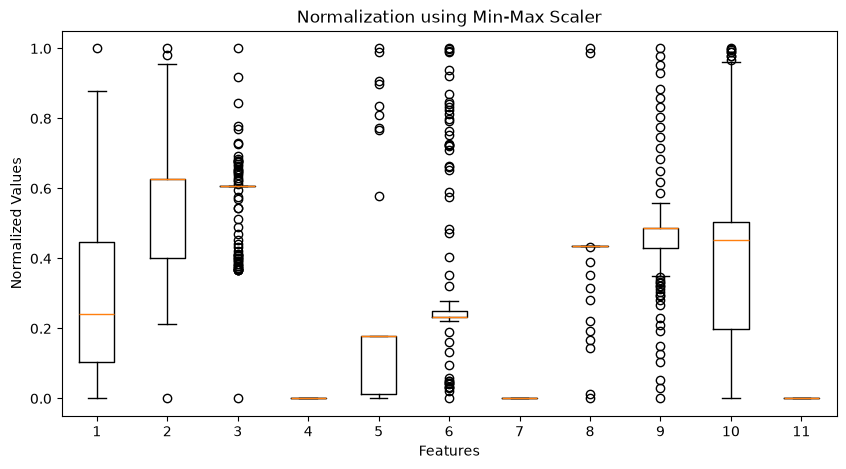

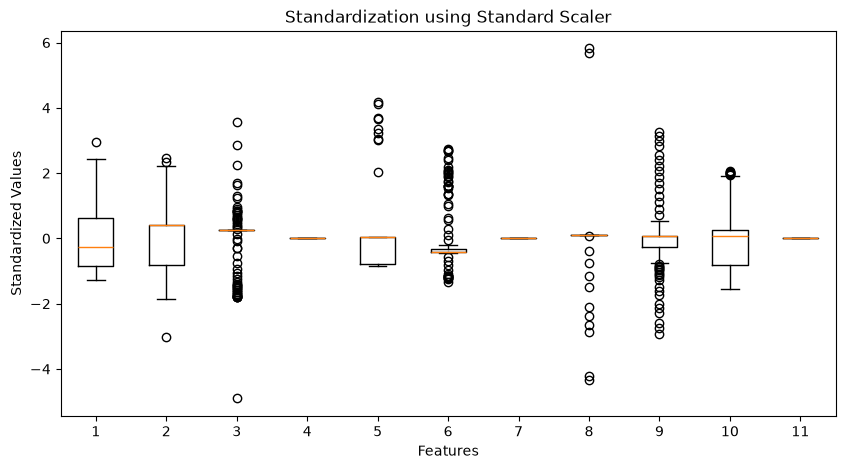


PCA Results:
   Principal Component 1  Principal Component 2
0              -0.730699              -0.193895
1              -0.949025               0.002127
2              -1.160931               0.199369
3              -1.376512               0.409438
4              -1.606047               0.640798

Explained Variance Ratio:
[0.43628028 0.20729357]

Total Explained Variance:
0.6435738472736311


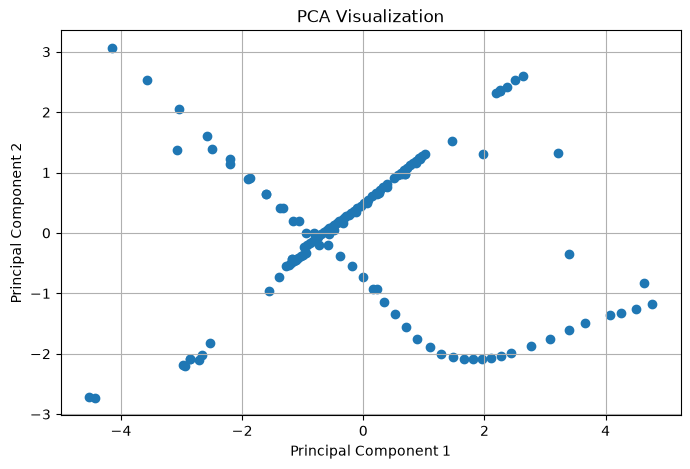

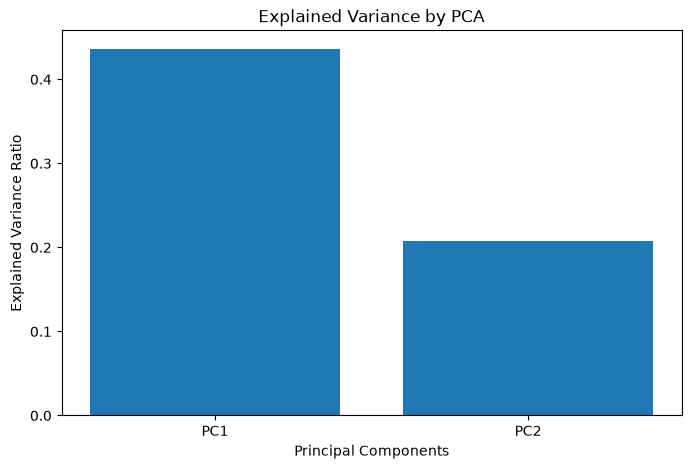

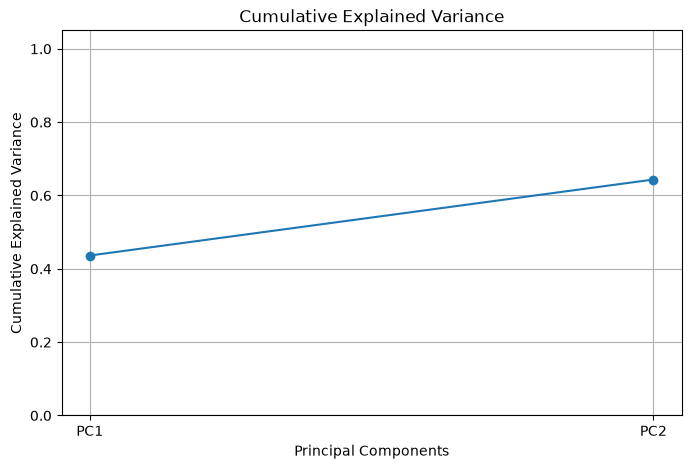


Original Dataset Shape: (499, 15)
Cleaned Dataset Shape: (133, 11)
PCA Dataset Shape: (133, 2)


In [8]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.decomposition import PCA

# 1. Load Dataset
df = pd.read_csv("World Economic Indicators - Sheet1.csv")

print("Original Dataset:")
print(df.head())

# 2. Data Cleaning

df = df.drop_duplicates()

data = df.select_dtypes(include=np.number).copy()

print("\nMissing Values Before Filling:")
print(data.isnull().sum())

# Mean and Median Filling
for col in data.columns:
    if data[col].isnull().any():
        if abs(data[col].skew()) > 0.5:
            data[col] = data[col].fillna(data[col].median())
            print(col, "-> Median Filling")
        else:
            data[col] = data[col].fillna(data[col].mean())
            print(col, "-> Mean Filling")

# Forward Fill only for country-wise yearly data
if 'Country' in df.columns and 'Year' in df.columns:
    df = df.sort_values(['Country', 'Year'])
    data = data.loc[df.index]
    data = data.groupby(df['Country']).ffill()

print("\nCleaned Data:")
print(data.head())

print("\nMissing Values After Filling:")
print(data.isnull().sum())

# 3. Outlier Detection and Removal using IQR

Q1 = data.quantile(0.25)
Q3 = data.quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outlier_condition = ((data < lower) | (data > upper)).any(axis=1)

print("\nNumber of Outliers:", outlier_condition.sum())

data = data[~outlier_condition].copy()

print("\nData After Outlier Removal:")
print(data.head())

# 4. Normalization
minmax = MinMaxScaler()

normalized_data = minmax.fit_transform(data)

normalized_df = pd.DataFrame(
    normalized_data, columns=data.columns
)

print("\nNormalized Data:")
print(normalized_df.head())

# 5. Standardization
standard = StandardScaler()

standardized_data = standard.fit_transform(data)

standardized_df = pd.DataFrame(
    standardized_data, columns=data.columns
)

print("\nStandardized Data:")
print(standardized_df.head())

# Visualization 1: Normalization Graph
plt.figure(figsize=(10, 5))
plt.boxplot(normalized_data)
plt.title("Normalization using Min-Max Scaler")
plt.xlabel("Features")
plt.ylabel("Normalized Values")
plt.show()

# Visualization 2: Standardization Graph
plt.figure(figsize=(10, 5))
plt.boxplot(standardized_data)
plt.title("Standardization using Standard Scaler")
plt.xlabel("Features")
plt.ylabel("Standardized Values")
plt.show()

# 6. PCA
pca = PCA(n_components=2)

pca_data = pca.fit_transform(standardized_data)

pca_df = pd.DataFrame(
    pca_data,
    columns=['Principal Component 1', 'Principal Component 2']
)

print("\nPCA Results:")
print(pca_df.head())

# Explained Variance
print("\nExplained Variance Ratio:")
print(pca.explained_variance_ratio_)

print("\nTotal Explained Variance:")
print(sum(pca.explained_variance_ratio_))

# Visualization 3: PCA Scatter Plot
plt.figure(figsize=(8, 5))
plt.scatter(pca_data[:, 0], pca_data[:, 1])

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Visualization")
plt.grid(True)
plt.show()

# Visualization 4: Explained Variance Bar Graph
plt.figure(figsize=(8, 5))
plt.bar(['PC1', 'PC2'], pca.explained_variance_ratio_)

plt.xlabel("Principal Components")
plt.ylabel("Explained Variance Ratio")
plt.title("Explained Variance by PCA")
plt.show()

# Visualization 5: Cumulative Explained Variance
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

plt.figure(figsize=(8, 5))
plt.plot(['PC1', 'PC2'], cumulative_variance, marker='o')

plt.xlabel("Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("Cumulative Explained Variance")
plt.ylim(0, 1.05)
plt.grid(True)
plt.show()

# 7. Display Dataset Shape
print("\nOriginal Dataset Shape:", df.shape)
print("Cleaned Dataset Shape:", data.shape)
print("PCA Dataset Shape:", pca_df.shape)
